# Model 03 · If I lie down for 5 minutes, will I wake up?
Two heads: log-duration regression (how long the "5 minutes" really lasts) and a classifier for waking within 30 minutes.

In [1]:
import sys
sys.path.insert(0, "../_shared")
try:
    import kit
except ImportError:
    from google.colab import files; files.upload(); import kit
from kit import *

## 1 · Dataset generator
Sleepiness is a sum of defendable effects (sleep debt, comfort, heat, post-lunch slump, workload, weekend) plus a hidden trait.
Duration is log-normal. A near-dead phone means no alarm, which stretches the nap.

In [2]:
DAYS = ["mon", "tue", "wed", "thu", "fri", "sat", "sun"]
def generate(n=10000, seed=SEED):
    r = np.random.default_rng(seed)
    hour = np.where(r.random(n) < .75, r.uniform(12, 19, n), r.uniform(19, 26, n) % 24)
    d = pd.DataFrame({"hour": np.round(hour, 1), "sleep_last": np.round(np.clip(r.normal(6.4, 1.4, n), 2, 10), 1),
        "bed_comfort": r.choice([1, 2, 3, 4, 5], n, p=[.05, .15, .3, .3, .2]), "temp_c": np.round(np.clip(r.normal(29, 5, n), 15, 42)),
        "day": r.choice(DAYS, n), "prev_naps": np.clip(r.poisson(1.2, n), 0, 5), "workload": r.integers(0, 11, n),
        "battery": np.round(np.clip(r.beta(2.2, 1.6, n) * 100, 1, 100))})
    hidden = r.normal(0, 1, n); weekend = d.day.isin(["sat", "sun"]).astype(float)
    drowsy = (0.55 * (8 - d.sleep_last).clip(0) + 0.30 * (d.bed_comfort - 3) + 0.06 * (d.temp_c - 28) + 0.5 * ((d.hour >= 13) & (d.hour < 16))
              + 0.04 * d.workload + 0.2 * d.prev_naps + 0.4 * weekend + 0.5 * hidden + 0.12 * (d.bed_comfort - 3) * (d.sleep_last < 5.5))
    dur = np.exp(np.log(9) + 0.55 * drowsy + r.normal(0, 0.45, n)) * np.where(d.battery < 8, 1.5, 1.0)
    d["duration_min"] = np.round(np.clip(dur, 3, 480), 1); d["wakes_on_time"] = (d.duration_min <= 30).astype(int)
    from scipy.stats import norm
    d["p_true"] = norm.cdf((np.log(30) - np.log(9) - 0.55 * drowsy) / 0.45)
    return d

In [3]:
df = generate(10000); df.drop(columns="p_true").to_csv("dataset.csv", index=False)
print(df.shape, "| wakes on time:", round(df.wakes_on_time.mean(), 3), "| median nap (min):", df.duration_min.median()); df.drop(columns="p_true").head()

(10000, 11) | wakes on time: 0.605 | median nap (min): 24.7


,hour,sleep_last,bed_comfort,temp_c,day,prev_naps,workload,battery,duration_min,wakes_on_time
0,0.2,3.7,2,30.0,sat,0,0,11.0,47.3,0
1,17.0,5.2,5,26.0,sun,1,2,28.0,74.8,0
2,19.3,5.0,3,25.0,fri,1,3,92.0,8.4,1
3,12.3,5.5,4,38.0,tue,1,4,82.0,44.7,0
4,14.1,6.8,5,29.0,mon,1,6,69.0,33.6,0


## 2 · Cleaning + EDA

nulls: 0 | duplicates: 0


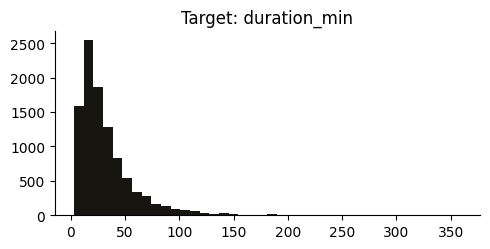

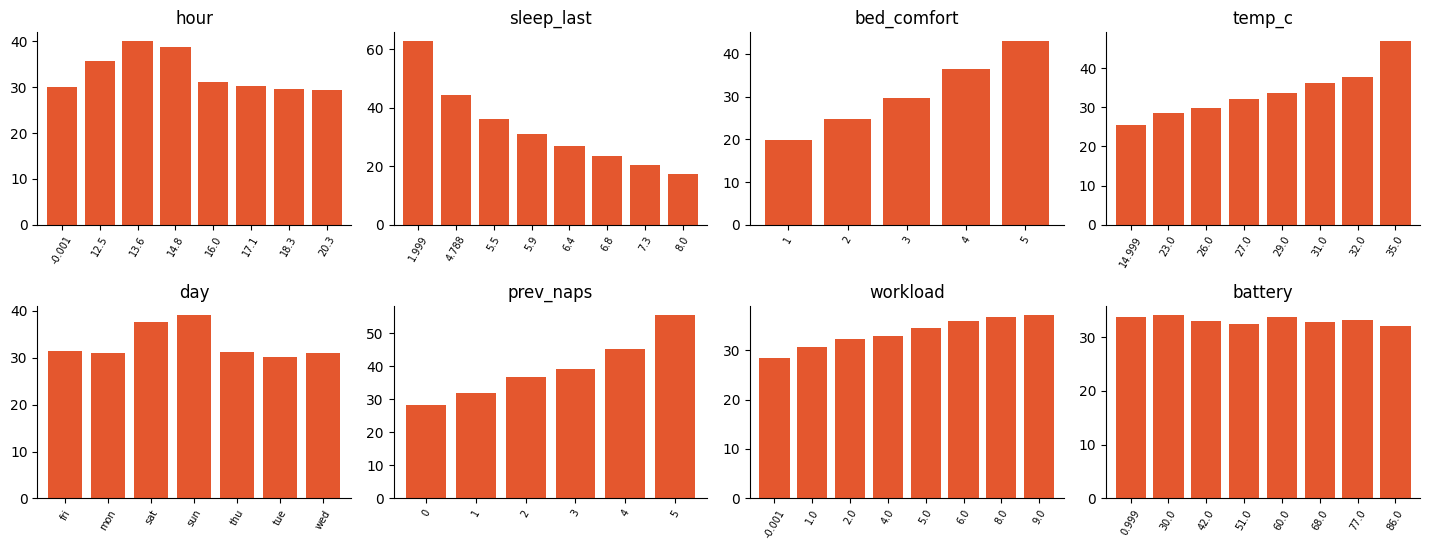

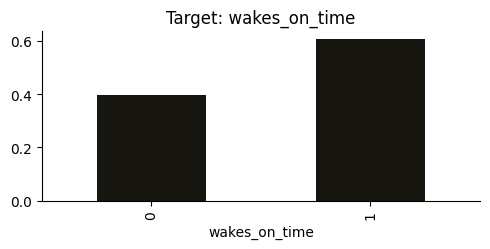

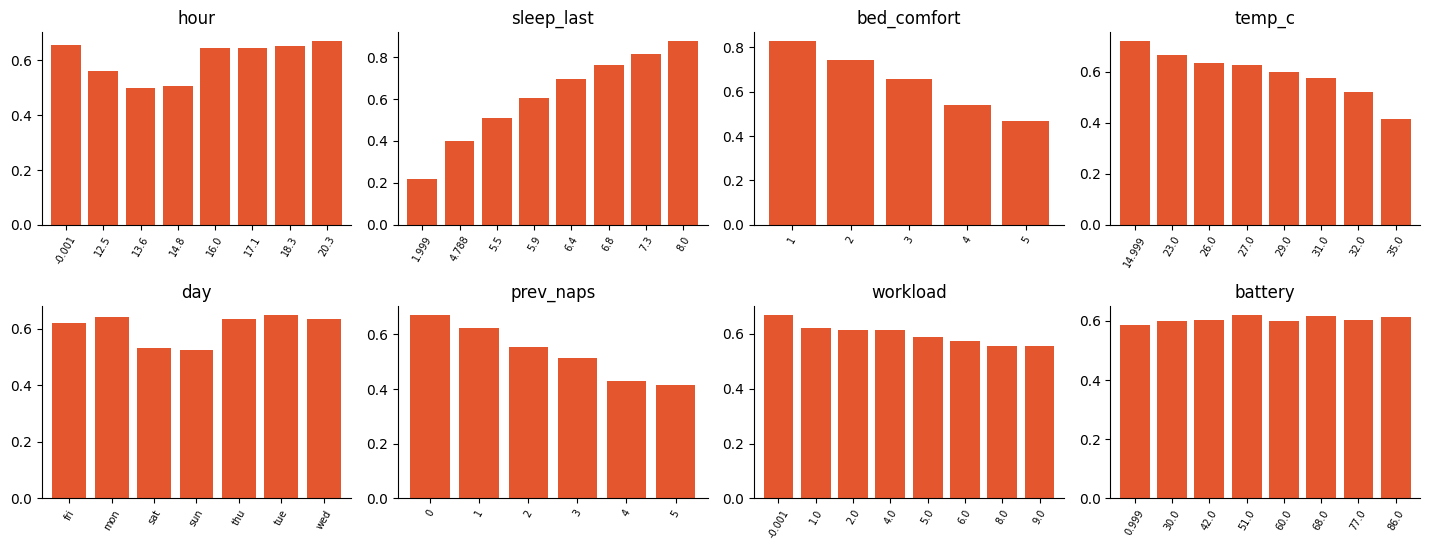

In [4]:
print("nulls:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))
INPUTS = [Num("hour", 0, 24, "cyc"), Num("sleep_last", 0, 12), Num("bed_comfort", 1, 5), Num("temp_c", 10, 45), Cat("day", DAYS),
          Num("prev_naps", 0, 5), Num("workload", 0, 10), Num("battery", 0, 100)]
RAW = [s["name"] for s in INPUTS]; eda(df, "duration_min", RAW, "regression"); eda(df, "wakes_on_time", RAW)

## 3 · Features, split, train both heads

In [5]:
fz = Featurizer(INPUTS); tr, va, te = split3(df, "wakes_on_time")
Xtr, Xva, Xte = fz.transform(tr), fz.transform(va), fz.transform(te)
dur, dur_val = train_regressor(Xtr, tr.duration_min.to_numpy(), Xva, va.duration_min.to_numpy(), log_target=True, depth=9, leaf=20)
wake, wake_name, table = train_classifier(Xtr, tr.wakes_on_time, Xva, va.wakes_on_time, depth=8, leaf=25)
print("duration head val:", {k: round(v, 2) for k, v in dur_val.items()}, "| wake head:", wake_name); table.round(4)

duration head val: {'val_mae': 14.0, 'ridge_baseline_val_mae': 13.76} | wake head: Logistic Regression


,model,val_log_loss,val_accuracy
0,Logistic Regression,0.4985,0.7573
1,Random Forest (isotonic-calibrated),0.5554,0.7500


## 4 · Test evaluation

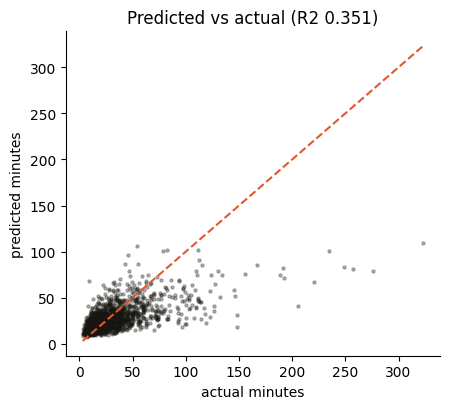

{'mae': 14.1102, 'r2': 0.3513}

In [6]:
m_dur = report_regression(dur, Xte, te.duration_min.to_numpy(), "minutes"); m_dur

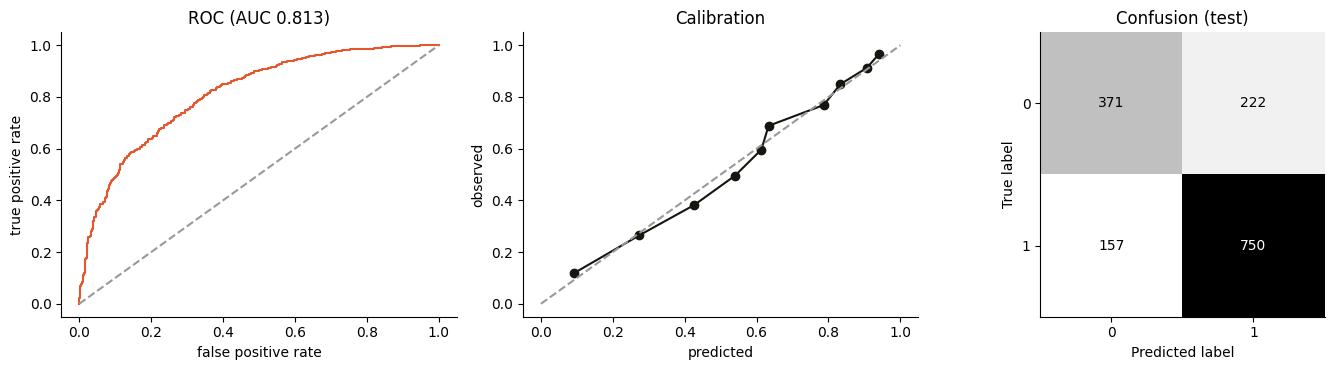

{'accuracy': 0.7473, 'roc_auc': 0.8127, 'log_loss': 0.5111, 'brier': 0.1699}

In [7]:
m_wake = report_binary(wake, Xte, te.wakes_on_time); m_wake

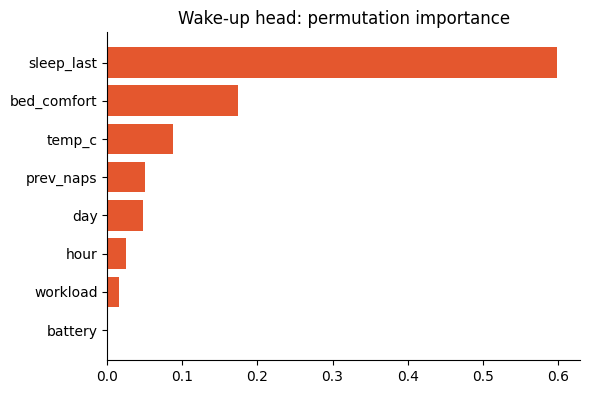

{'sleep_last': 0.5997,
 'bed_comfort': 0.1735,
 'temp_c': 0.0878,
 'prev_naps': 0.0507,
 'day': 0.0473,
 'hour': 0.0254,
 'workload': 0.0156,
 'battery': 0.0}

In [8]:
imp = group_importance(lambda X: wake.predict_proba(X)[:, 1], Xte, te.wakes_on_time.to_numpy(), fz.groups, lambda y, p: log_loss(y, p))
plot_importance(imp, "Wake-up head: permutation importance"); imp

In [9]:
ex = pd.DataFrame([dict(hour=15, sleep_last=4.5, bed_comfort=5, temp_c=34, day="sun", prev_naps=2, workload=8, battery=6),
                   dict(hour=17, sleep_last=8, bed_comfort=2, temp_c=24, day="tue", prev_naps=0, workload=2, battery=70)])
X = fz.transform(ex); ex["P(wake)"] = wake.predict_proba(X)[:, 1].round(3); ex["nap (min)"] = dur.predict(X).round(0); ex

,hour,sleep_last,bed_comfort,temp_c,day,prev_naps,workload,battery,P(wake),nap (min)
0,15,4.5,5,34,sun,2,8,6,0.026,75.0
1,17,8.0,2,24,tue,0,2,70,0.986,8.0


## 5 · Export + verify

In [10]:
heads = {"wake": export_head(wake, labels=["no", "yes"]), "duration": export_head(dur, task="regression")}
meta = make_metadata("v1.0", SEED, len(df), {"train": len(tr), "val": len(va), "test": len(te)},
    {"wake": {"algorithm": wake_name, "task": "binary", "metrics": m_wake, "candidates": table.round(4).to_dict("records")},
     "duration": {"algorithm": "Random Forest Regressor (log target)", "task": "regression", "metrics": m_dur}},
    imp, ["Synthetic data. Real nap length depends on things this model has never met (your landlord, your cat, a 3 pm lecture).", "Risk bands are fixed thresholds on wake-up probability."], "generate() in this notebook")
write_artifacts("model", "nap", "If I lie down for 5 minutes, will I wake up?", fz, tr, heads, {"wake": wake, "duration": dur}, meta, te[RAW])

wrote model (249 KB total) | export error vs sklearn: {'wake': 3.4493269351898448e-09, 'duration': 4.967708196356588e-07}


{'wake': 3.4493269351898448e-09, 'duration': 4.967708196356588e-07}